# Aplicación y evaluación de RUSLE en la cuenca del Lago Villarrica (REN237)


In [ ]:
import ee
import geemap
import geopandas as gpd
import pandas as pd

**Pasos para activar su cuenta de Google con un proyecto GEE**

1. Crear cuenta de Google (si no tienen una)

2. Ir a https://earthengine.google.com/signup/ e iniciar sesión con su cuenta de Google. Completar el formulario de registro seleccionando 'Uso no comercial / académico'
3. Crear un proyecto en Google Cloud Console
Ir a https://console.cloud.google.com/projectcreate, ponerle un nombre al proyecto (ej. 'clase-erosion-nombre') y anotar ese Project ID
4. Habilitar la API de Earth Engine en el proyecto
Con el proyecto creado y seleccionado, ir a https://console.cloud.google.com/apis/library/earthengine.googleapis.com y hacer clic en 'Habilitar'
5. Registrar el proyecto para uso con Earth Engine
Ir a https://console.cloud.google.com/earth-engine/configuration y seguir los indicando que es para investigación/uso académico no comercial.


In [ ]:
GEE_PROJECT = 'conservacion-de-suelos-507315'

import ee

print("Autenticando...")
ee.Authenticate()

print(f"Inicializando proyecto: {GEE_PROJECT}...")
try:
    ee.Initialize(project=GEE_PROJECT)
    print("✓ Google Earth Engine inicializado correctamente!")

    info = ee.Number(1).getInfo()
    print("✓ Conexión verificada.")

except ee.EEException as e:
    print(f"\n✗ Falló la inicialización: {e}")
    if "not registered" in str(e):
        print(f"\nACCIÓN REQUERIDA: El proyecto '{GEE_PROJECT}' no está registrado en Earth Engine.")
        print(f"1. Regístralo aquí: https://console.cloud.google.com/earth-engine/configuration?project={GEE_PROJECT}")
        print("2. O actualiza la variable GEE_PROJECT con un Project ID válido.")
    elif "permission" in str(e).lower():
        print(f"\nACCIÓN REQUERIDA: Puede que no tengas permisos para el proyecto '{GEE_PROJECT}'.")
        print("Revisa la configuración de IAM en Google Cloud Console.")
except Exception as e:
    print(f"\n✗ Ocurrió un error inesperado: {e}")

Autenticando...
Inicializando proyecto: conservacion-de-suelos-507315...
✓ Google Earth Engine inicializado correctamente!
✓ Conexión verificada.


In [ ]:
# Cuenca del Lago Villarrica: capa de pérdida potencial del Inventario de Erosión de CIREN (r09_033_rep_1ha)
from google.colab import drive
drive.mount('/content/drive')   # necesario en cada sesión para leer la copia guardada en Drive

gp_df = gpd.read_file('/content/drive/MyDrive/RUSLE/r09_033_rep_1ha.gpkg')
gp_df_simple = gp_df.dissolve()                         # une las celdas de 1 ha y deja solo el contorno de la cuenca
area_de_interes = geemap.geopandas_to_ee(gp_df_simple)  # el contorno pasa a GEE para recortar y resumir las demás capas

Mounted at /content/drive


In [ ]:
# Visualizamos el area de interes
mapa_simple = geemap.Map(basemap="Esri.WorldImagery")
mapa_simple.centerObject(area_de_interes, zoom=12)
mapa_simple.addLayer(area_de_interes.style(color="black", fillColor="00000000", width=2), {}, "Área de interés")
mapa_simple

Map(center=[-39.28303962635838, -72.06108359599388], controls=(WidgetControl(options=['position', 'transparent…

---
## ETAPA 1. Pérdida potencial de CIREN (C = P = 1)


In [ ]:
# E1.1 Revisión de la capa de CIREN

# Primero se revisa qué trae la capa, porque los nombres de campos y sus tipos (texto o número)
# determinan cómo se clasifica después y hay que evitar errores de arrastre
print("Polígonos (celdas de 1 ha):", len(gp_df))
print("Sistema de coordenadas:", gp_df.crs)          # debe ser EPSG:32719 (UTM 19S, metros)
print("Campos:", list(gp_df.columns))

# Códigos de rango y clases presentes en la cuenca, para confirmar que calzan con la tabla de CIREN
print(gp_df[['COD_RANGO', 'RANGO', 'CLASEROS']].drop_duplicates().sort_values('COD_RANGO'))

# Se crea un código entero porque el campo puede venir como texto y GEE solo rasteriza propiedades numéricas
gp_df['cod_num'] = gp_df['COD_RANGO'].astype(int)

# el área declarada por CIREN (AREA_HA) contra el área calculada de la geometría deben ser iguales.
# Si difieren mucho, hay que decidir cuál reportar y explicarlo en la metodología y supuestos.
area_geom_ha = gp_df.geometry.area / 1e4
print(f"\nÁrea total según AREA_HA:   {gp_df['AREA_HA'].sum():,.1f} ha")
print(f"Área total según geometría: {area_geom_ha.sum():,.1f} ha")

# Rango de la tasa RUSLE de CIREN (t/ha/año), para verificar el orden de magnitud antes de clasificar
print("\nRUSLE (t/ha/año):", gp_df['RUSLE'].describe().round(2).to_dict())

Polígonos (celdas de 1 ha): 30474
Sistema de coordenadas: EPSG:32719
Campos: ['id', 'COD_REG', 'ID_RUSLE', 'ESCALA', 'CODICLASE', 'CODISUBCLA', 'SUBCLASERO', 'COD_RANGO', 'RANGO', 'CLASEROS', 'RUSLE', 'AREA_HA', 'geometry']
    COD_RANGO      RANGO          CLASEROS
14          1      0 - 5              NULA
47          2     5 - 10          MUY LEVE
90          3    10 - 25              LEVE
39          4    25 - 50   MODERADA - LEVE
17          5   50 - 100  MODERADA - GRAVE
19          6  100 - 200             GRAVE
26          7      > 200         MUY GRAVE
0         999  NO SUELOS         NO SUELOS

Área total según AREA_HA:   49,475.6 ha
Área total según geometría: 49,475.6 ha

RUSLE (t/ha/año): {'count': 30474.0, 'mean': 198.89, 'std': 175.13, 'min': 0.0, '25%': 70.0, '50%': 100.0, '75%': 300.0, 'max': 500.0}


In [ ]:
# E1.2 Tabla de superficie por clase

# Nombres y rangos oficiales de CIREN por código, para que la tabla use su nomenclatura y su orden
CLASES_CIREN = {
    1: ('0-5', 'Nula'), 2: ('5-10', 'Muy leve'), 3: ('10-25', 'Leve'),
    4: ('25-50', 'Moderada-leve'), 5: ('50-100', 'Moderada-grave'),
    6: ('100-200', 'Grave'), 7: ('>200', 'Muy grave'),
    999: ('—', 'No suelos'),   # en esta capa, el 999 es "NO SUELOS" (lago, zona urbana, roca), según E1.1
}

# Suma la superficie que reporta CIREN (AREA_HA) por código de clase, para que la tabla sea comparable con su inventario
ha_por_clase = gp_df.groupby('cod_num')['AREA_HA'].sum()

# Superficie total y superficie con suelo (clases 1 a 7). Se separan porque el lago y la zona urbana
# (No suelos) ocupan una fracción grande y diluirían la importancia de las clases erosivas
area_total = ha_por_clase.sum()
area_suelos = 0
for codigo in range(1, 8):
    area_suelos = area_suelos + ha_por_clase.get(codigo, 0)   # .get(codigo, 0): 0 ha si la clase no aparece

# Una fila por clase de CIREN
filas = []
for codigo in CLASES_CIREN:
    ha_clase = ha_por_clase.get(codigo, 0)
    if codigo <= 7:
        pct_suelos = 100 * ha_clase / area_suelos
    else:
        pct_suelos = None          # No suelos y Sin información no se expresan como porcentaje del suelo
    filas.append({'Rango (t/ha/año)': CLASES_CIREN[codigo][0],
                  'Clase': CLASES_CIREN[codigo][1],
                  'ha': ha_clase,
                  '% cuenca': 100 * ha_clase / area_total,
                  '% suelos': pct_suelos})
tabla_vec = pd.DataFrame(filas)

print(tabla_vec.round(1).to_string(index=False))
print(f"\nTotal cuenca: {area_total:,.1f} ha | Superficie con suelo: {area_suelos:,.1f} ha")
tabla_vec.round(2).to_csv('etapa1_tabla_superficie_vectorial.csv', index=False, encoding='utf-8-sig')  # utf-8-sig para que Excel lea bien las tildes por si lo necesito, aunque no creo

Rango (t/ha/año)          Clase      ha  % cuenca  % suelos
             0-5           Nula  2762.5       5.6       9.9
            5-10       Muy leve   158.7       0.3       0.6
           10-25           Leve   414.7       0.8       1.5
           25-50  Moderada-leve   973.3       2.0       3.5
          50-100 Moderada-grave  4271.9       8.6      15.3
         100-200          Grave  7948.6      16.1      28.5
            >200      Muy grave 11313.5      22.9      40.6
               —      No suelos 21632.2      43.7       NaN

Total cuenca: 49,475.6 ha | Superficie con suelo: 27,843.3 ha


In [ ]:
# E1.3 Exportar la capa para subirla como asset de GEE

# GeoPackage en caso de necesitarlo
gp_df.to_file('r09_033_rep_1ha.gpkg', driver='GPKG')

# Shapefile solo con los campos necesarios para subirlo como asset en el Code Editor de GEE
gp_df[['cod_num', 'RUSLE', 'AREA_HA', 'geometry']].to_file('r09_033_rep_1ha_gee.shp')

In [ ]:
# E1.4 Llevar la capa de CIREN a GEE y rasterizarla

# Ya subida la capa como asset, enviarla directamente desde Python supera el límite de tamaño de una solicitud a GEE
ASSET_CIREN = f'projects/{GEE_PROJECT}/assets/r09_033_rep_1ha_gee'
fc_ciren = ee.FeatureCollection(ASSET_CIREN)

# Cada celda de CIREN pasa a píxel con su código de clase. reduceToImage exige una propiedad numérica,
# por eso se usa cod_num (entero).
clases_ciren = (fc_ciren
                .reduceToImage(properties=['cod_num'], reducer=ee.Reducer.first())
                .rename('cod_rango'))

In [ ]:
# E1.5 Tabla de superficie por clase calculada en GEE

# Superficie de cada píxel en hectáreas, agrupada por código de clase
area_por_clase = (ee.Image.pixelArea().divide(1e4)
                  .addBands(clases_ciren)
                  .reduceRegion(
                      reducer=ee.Reducer.sum().group(groupField=1, groupName='cod'),
                      geometry=area_de_interes.geometry(),
                      crs='EPSG:32719',   # misma proyección métrica que la capa de CIREN
                      scale=10,
                      maxPixels=1e10)     # sin bestEffort: si GEE cambiara la escala por su cuenta, el área quedaría mal calculada
                  .getInfo())

# GEE devuelve una lista de grupos y se pasa a un diccionario "código -> hectáreas"
ha_gee = {}
for g in area_por_clase['groups']:
    ha_gee[int(g['cod'])] = g['sum']
total_gee = sum(ha_gee.values())

# Comparación con la tabla vectorial, la diferencia viene de pasar polígonos a píxeles
# (los bordes se asignan al píxel más cercano). Se reporta para explicar diferencias entre plataformas.
filas = []
for codigo in CLASES_CIREN:
    ha_vector = ha_por_clase.get(codigo, 0)
    ha_raster = ha_gee.get(codigo, 0)
    if ha_vector > 0:
        diferencia = 100 * (ha_raster - ha_vector) / ha_vector
    else:
        diferencia = None          # sin superficie vectorial no hay porcentaje de diferencia que calcular
    filas.append({'Clase': CLASES_CIREN[codigo][1],
                  'ha (vectorial)': ha_vector,
                  'ha (GEE)': ha_raster,
                  '% cuenca (GEE)': 100 * ha_raster / total_gee,
                  'dif. (%)': diferencia})
comparacion = pd.DataFrame(filas)

print(comparacion.round(2).to_string(index=False))
comparacion.round(2).to_csv('etapa1_tabla_superficie_gee.csv', index=False, encoding='utf-8-sig')

         Clase  ha (vectorial)  ha (GEE)  % cuenca (GEE)  dif. (%)
          Nula         2762.53   3021.94            6.11      9.39
      Muy leve          158.72    187.66            0.38     18.23
          Leve          414.72    489.63            0.99     18.06
 Moderada-leve          973.34   1129.97            2.29     16.09
Moderada-grave         4271.89   4655.73            9.42      8.99
         Grave         7948.65   7938.49           16.06     -0.13
     Muy grave        11313.49  10898.35           22.05     -3.67
     No suelos        21632.22  21108.27           42.70     -2.42


In [ ]:
# E1.6 Mapa de pérdida potencial con las clases de CIREN
from ipyleaflet import ScaleControl # para agregar una escala gráfica al mapa interactivo de geemap

# Paleta de verde (nula) a rojo oscuro (muy grave), progresión de menor a mayor pérdida.
# Antes de la versión final, comparar con los colores del estilo oficial de la capa en el GeoNode de CIREN.
COLORES_CIREN = ['1a9850', '91cf60', 'd9ef8b', 'fee08b', 'fc8d59', 'd73027', '7f0000']

# Solo clases 1 a 7 en la paleta; "No suelos" y "Sin información" se muestran aparte en gris,
# para que el lago y la zona urbana no se confundan con pérdida nula
suelos = clases_ciren.updateMask(clases_ciren.lte(7))
no_suelos = clases_ciren.updateMask(clases_ciren.gte(998))

mapa_e1 = geemap.Map(basemap="Esri.WorldImagery")
mapa_e1.centerObject(area_de_interes, zoom=12)
mapa_e1.addLayer(suelos, {'min': 1, 'max': 7, 'palette': COLORES_CIREN}, 'Pérdida potencial CIREN', True, 0.85)
mapa_e1.addLayer(no_suelos, {'palette': ['bdbdbd']}, 'No suelos / sin información', True, 0.85)
mapa_e1.addLayer(area_de_interes.style(color='black', fillColor='00000000', width=2), {}, 'Área de interés')

# Leyenda con rango y nomenclatura de CIREN, como exige la rúbrica
leyenda = {'Nula (0-5)': '#1a9850', 'Muy leve (5-10)': '#91cf60', 'Leve (10-25)': '#d9ef8b',
           'Moderada-leve (25-50)': '#fee08b', 'Moderada-grave (50-100)': '#fc8d59',
           'Grave (100-200)': '#d73027', 'Muy grave (>200)': '#7f0000',
           'No suelos / sin información': '#bdbdbd'}
mapa_e1.add_legend(title="Pérdida potencial (t ha⁻¹ año⁻¹)", legend_dict=leyenda)

# Escala gráfica en el mapa interactivo (el norte se agrega en la versión estática para el informe)
mapa_e1.add(ScaleControl(position='bottomleft', metric=True, imperial=False))
mapa_e1

Map(center=[-39.28303962635834, -72.06108359599398], controls=(WidgetControl(options=['position', 'transparent…

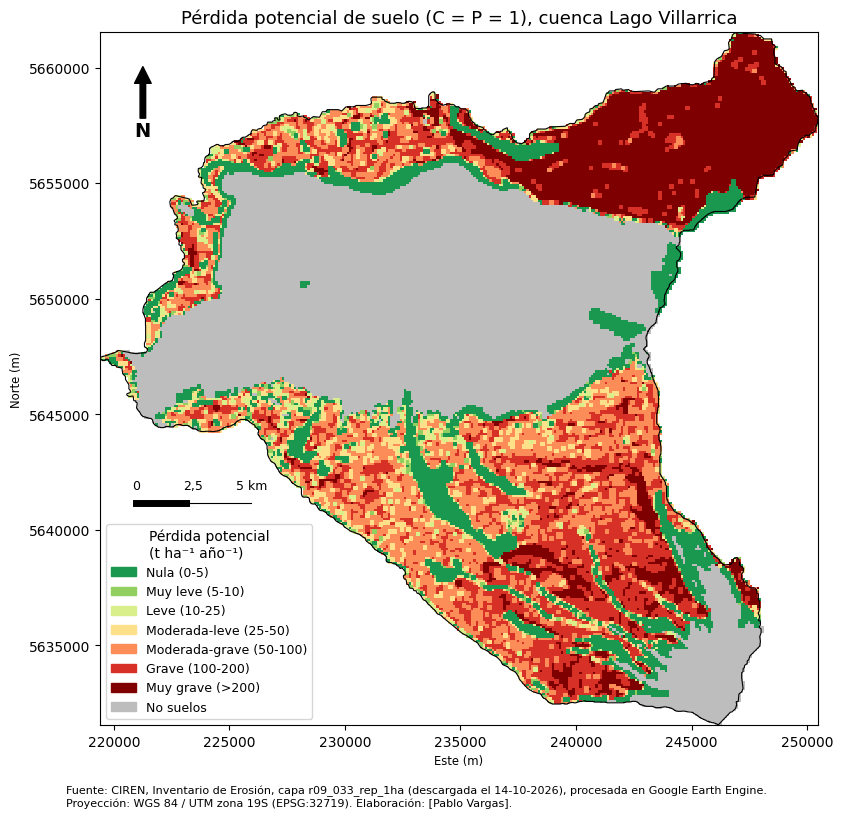

In [ ]:
# E1.7 Mapa estático de la pérdida potencial
import numpy as np # convierte la imagen que viene de GEE en una matriz de números
import matplotlib.pyplot as plt # para hacer el mapa estático, agrega título, ejes, flecha de norte, escala y texto de fuente, y lo guarda como imagen.
from matplotlib.colors import ListedColormap, BoundaryNorm # un color fijo por clase de CIREN
from matplotlib.patches import Patch # colores para la leyenda

# Rectángulo que contiene la unidad, en UTM 19S
xmin, ymin, xmax, ymax = gp_df.total_bounds
region = ee.Geometry.Rectangle([xmin, ymin, xmax, ymax], proj='EPSG:32719', geodesic=False)

# Se trae la imagen de clases desde GEE como matriz. A 100 m, cada píxel equivale a una celda de 1 ha de CIREN,
# y la matriz cabe dentro del límite de sampleRectangle. defaultValue=0 marca los píxeles fuera de la unidad.
matriz = np.array(clases_ciren.reproject(crs='EPSG:32719', scale=100)
                  .sampleRectangle(region=region, defaultValue=0)
                  .get('cod_rango').getInfo())

# Para la paleta, "No suelos" (999) pasa a 8, y lo que está fuera de la unidad (0) queda sin color
matriz = np.where(matriz == 999, 8, matriz).astype(float)
matriz[matriz == 0] = np.nan

# Colores de las clases 1 a 7 (los mismos del mapa interactivo) más gris para No suelos
colores = ['#' + c for c in COLORES_CIREN] + ['#bdbdbd']
paleta = ListedColormap(colores)
limites = BoundaryNorm(np.arange(0.5, 9.5, 1), paleta.N)   # un color por valor entero de 1 a 8

fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(matriz, cmap=paleta, norm=limites, extent=[xmin, xmax, ymin, ymax], interpolation='nearest')
gp_df_simple.boundary.plot(ax=ax, color='black', linewidth=0.8)   # contorno de la unidad

# Leyenda con la nomenclatura y los rangos de CIREN
elementos = []
for codigo in range(1, 8):
    elementos.append(Patch(color=colores[codigo - 1],
                           label=f"{CLASES_CIREN[codigo][1]} ({CLASES_CIREN[codigo][0]})"))
elementos.append(Patch(color='#bdbdbd', label='No suelos'))
ax.legend(handles=elementos, title='Pérdida potencial\n(t ha⁻¹ año⁻¹)', loc='lower left', fontsize=9, title_fontsize=10)

# Flecha de norte
ax.annotate('N', xy=(0.06, 0.95), xytext=(0.06, 0.85), xycoords='axes fraction', ha='center',
            fontsize=14, fontweight='bold', arrowprops=dict(facecolor='black', width=4, headwidth=12))

# Escala gráfica de 5 km
x0 = xmin + 0.05 * (xmax - xmin)
y0 = ymin + 0.32 * (ymax - ymin)
ax.plot([x0, x0 + 2500], [y0, y0], color='black', linewidth=5)
ax.plot([x0 + 2500, x0 + 5000], [y0, y0], color='white', linewidth=5)
ax.plot([x0, x0 + 5000], [y0, y0], color='black', linewidth=0.8)
ax.text(x0, y0 + 600, '0', ha='center', fontsize=9)
ax.text(x0 + 2500, y0 + 600, '2,5', ha='center', fontsize=9)
ax.text(x0 + 5000, y0 + 600, '5 km', ha='center', fontsize=9)

ax.set_title('Pérdida potencial de suelo (C = P = 1), cuenca Lago Villarrica', fontsize=13)
ax.set_xlabel('Este (m)')
ax.set_ylabel('Norte (m)')
ax.ticklabel_format(style='plain')

fig.text(0.12, 0.02,
         'Fuente: CIREN, Inventario de Erosión, capa r09_033_rep_1ha (descargada el 14-10-2026), procesada en Google Earth Engine.\n'
         'Proyección: WGS 84 / UTM zona 19S (EPSG:32719). Elaboración: [Pablo Vargas].',
         fontsize=8)

fig.savefig('/content/drive/MyDrive/RUSLE/figura1b_potencial_gee.png', dpi=300, bbox_inches='tight')
plt.show()

---
## ETAPA 2. Cambio del factor C


In [ ]:
# Precipitación de ambas ventanas. Hay un 9% de cambio dentro de un margen razonable, así que el par de años sirve para comparar NDVI.
for inicio, fin in [('2013-04-01', '2014-04-01'), ('2023-04-01', '2024-04-01')]:
    p = (ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY').filterDate(inicio, fin)
         .select('precipitation').sum()
         .reduceRegion(ee.Reducer.mean(), area_de_interes.geometry(), 5566).getInfo())
    print(f"{inicio} a {fin}: {p['precipitation']:.0f} mm")

2013-04-01 a 2014-04-01: 1606 mm
2023-04-01 a 2024-04-01: 1754 mm


In [ ]:
# NDVI de dos periodos (2013-14 y 2023-24) con el mismo método

def enmascarar_nubes(img):
    # QA_PIXEL de Landsat Collection 2 marca cada píxel: bit 1 = nube dilatada, bit 3 = nube, bit 4 = sombra.
    # Se eliminan esos píxeles, porque nubes y sombras bajan el NDVI y harían parecer que hay menos vegetación.
    qa = img.select('QA_PIXEL')
    mascara = (qa.bitwiseAnd(1 << 1).eq(0)
               .And(qa.bitwiseAnd(1 << 3).eq(0))
               .And(qa.bitwiseAnd(1 << 4).eq(0)))
    return img.updateMask(mascara)

def calcular_ndvi(inicio, fin, etiqueta):
    # Una sola función para ambos periodos garantiza que se calculen exactamente con el mismo método
    col = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')   # Landsat 8 nivel 2: mismo sensor en ambos periodos
           .filterBounds(area_de_interes)
           .filterDate(inicio, fin)                      # misma ventana abril-marzo (año hidrológico), para evitar diferencias estacionales
           .filter(ee.Filter.lt('CLOUD_COVER', 30))      # descarta escenas muy nubladas antes de enmascarar píxel a píxel
           .map(enmascarar_nubes))
    print(f"{etiqueta}: {col.size().getInfo()} escenas")   # pocas escenas = compuesto menos confiable

    # Mediana: reduce el efecto de nubes residuales y sombras que quedan tras el enmascarado
    comp = (col.median()
            .select(['SR_B5', 'SR_B4'])                  # infrarrojo cercano y rojo, las bandas del NDVI
            .multiply(0.0000275).add(-0.2)               # factor de escala de Collection 2 para pasar a reflectancia
            .clip(area_de_interes))
    return comp.normalizedDifference(['SR_B5', 'SR_B4']).rename('NDVI')

ndvi_1314 = calcular_ndvi('2013-04-01', '2014-04-01', '2013-14')
ndvi_2324 = calcular_ndvi('2023-04-01', '2024-04-01', '2023-24')

# Dos máscaras con propósitos distintos:
# 1) Tierra (todo menos agua): para describir el cambio de cobertura, incluida la expansión urbana.
#    Se considera agua el píxel cubierto por agua al menos el 50% del tiempo (JRC Global Surface Water, 1984-2021).
agua = (ee.Image('JRC/GSW1_4/GlobalSurfaceWater')
        .select('occurrence')
        .unmask(0)          # fuera del agua el dataset no tiene dato y se rellena con 0 = nunca agua
        .gte(50))
mascara_tierra = agua.Not()

# 2) Suelos según CIREN (clases 1 a 7): para C y RUSLE, que no aplican sobre superficies selladas (urbano, caminos)
mascara_suelos = clases_ciren.lte(7)

ndvi_1314 = ndvi_1314.updateMask(mascara_tierra)
ndvi_2324 = ndvi_2324.updateMask(mascara_tierra)

# NDVI medio de cada periodo sobre toda la tierra (incluye zonas urbanas)
media_ndvi_1314 = ndvi_1314.reduceRegion(ee.Reducer.mean(), area_de_interes.geometry(),
                                         scale=30, maxPixels=1e9, bestEffort=True).getInfo()
media_ndvi_2324 = ndvi_2324.reduceRegion(ee.Reducer.mean(), area_de_interes.geometry(),
                                         scale=30, maxPixels=1e9, bestEffort=True).getInfo()
print(f"NDVI medio 2013-14 (tierra): {media_ndvi_1314['NDVI']:.3f}")
print(f"NDVI medio 2023-24 (tierra): {media_ndvi_2324['NDVI']:.3f}")

# Una diferencia de NDVI negativa = pérdida de vegetación, positivo = ganancia.
# Usa la máscara de tierra, así que muestra también el cambio en zonas urbanas.
dif_ndvi = ndvi_2324.subtract(ndvi_1314).rename('dif_NDVI')

viz_ndvi = {'min': 0, 'max': 0.8, 'palette': ['brown', 'yellow', 'lightgreen', 'darkgreen']}
viz_dif = {'min': -0.3, 'max': 0.3, 'palette': ['b2182b', 'f7f7f7', '1a9850']}   # rojo = pérdida, verde = ganancia

mapa_ndvi = geemap.Map(basemap="Esri.WorldImagery")
mapa_ndvi.centerObject(area_de_interes, zoom=12)
mapa_ndvi.addLayer(ndvi_1314, viz_ndvi, 'NDVI 2013-14', False)
mapa_ndvi.addLayer(ndvi_2324, viz_ndvi, 'NDVI 2023-24', False)
mapa_ndvi.addLayer(dif_ndvi, viz_dif, 'Diferencia NDVI (2023-24 menos 2013-14)')
mapa_ndvi.addLayer(area_de_interes.style(color='black', fillColor='00000000', width=2), {}, 'Área de interés')
mapa_ndvi.add_colorbar(viz_dif, label='Diferencia de NDVI')
mapa_ndvi

2013-14: 29 escenas
2023-24: 32 escenas
NDVI medio 2013-14 (tierra): 0.764
NDVI medio 2023-24 (tierra): 0.764


Map(center=[-39.28303962635834, -72.06108359599398], controls=(WidgetControl(options=['position', 'transparent…

In [ ]:
# Diagnóstico del cambio de cobertura

# El promedio puede ocultar cambios locales que se compensan, así que se revisan los extremos de la distribución
p = dif_ndvi.reduceRegion(
    # Los percentiles 5 y 95 muestran las pérdidas y ganancias más fuertes de vegetación, y el 50 es la mediana.
    # combine agrega el promedio en el mismo cálculo, y sharedInputs=True indica que ambos usan la misma imagen
    ee.Reducer.percentile([5, 50, 95]).combine(ee.Reducer.mean(), sharedInputs=True),
    area_de_interes.geometry(),
    scale=30,                # resolución de Landsat, la misma del NDVI
    maxPixels=1e9,
    bestEffort=True          # aquí sí se permite que GEE ajuste la escala, porque son estadísticos y no áreas
).getInfo()                  # trae los resultados del servidor de GEE a Python

# Si la media es cercana a 0 pero p5 y p95 son grandes, hubo pérdidas y ganancias que se compensan
print(f"Diferencia de NDVI: media = {p['dif_NDVI_mean']:.3f} | p5 = {p['dif_NDVI_p5']:.3f} | "
      f"mediana = {p['dif_NDVI_p50']:.3f} | p95 = {p['dif_NDVI_p95']:.3f}")

# Superficie con pérdida o ganancia marcada de vegetación. Umbral de 0,1: cambios menores
# se confunden con ruido entre compuestos (diferencias de iluminación, nubes residuales)
cambio = (ee.Image(0)
          .where(dif_ndvi.lt(-0.1), -1)
          .where(dif_ndvi.gt(0.1), 1)
          .updateMask(dif_ndvi.mask())     # solo tierra, igual que dif_ndvi
          .rename('cambio'))
res = (ee.Image.pixelArea().divide(1e4).addBands(cambio)
       .reduceRegion(ee.Reducer.sum().group(groupField=1, groupName='cambio'),
                     area_de_interes.geometry(), scale=30, maxPixels=1e10)   # sin bestEffort: es un cálculo de área
       .getInfo())

# Se pasa a un diccionario "código de cambio → hectáreas" para imprimir cada categoría
ha_cambio = {}
for g in res['groups']:
    ha_cambio[int(g['cambio'])] = g['sum']
print(f"Pérdida (< -0,1):   {ha_cambio.get(-1, 0):>8,.0f} ha")
print(f"Sin cambio marcado: {ha_cambio.get(0, 0):>8,.0f} ha")
print(f"Ganancia (> 0,1):   {ha_cambio.get(1, 0):>8,.0f} ha")

Diferencia de NDVI: media = 0.000 | p5 = -0.117 | mediana = -0.008 | p95 = 0.117
Pérdida (< -0,1):      1,921 ha
Sin cambio marcado:   27,924 ha
Ganancia (> 0,1):      2,090 ha


In [ ]:
# C por clase de cobertura: De Jong (NDVI) con un piso distinto según la clase de MapBiomas

# Mapas anuales de cobertura de MapBiomas Chile (Colección 2.0), 30 m, misma resolución que el NDVI
mapbiomas = ee.Image('projects/mapbiomas-chile/assets/LULC/COLLECTION-02/CLASSIFICATIONS/classification-final/clasificacion-final-2')

# 2013 y 2023 son los años que más meses cubren de las ventanas de NDVI (abril a marzo, año hidrológico 13-14 y 23-24)
clase_mb_2013 = mapbiomas.select('classification_2013')
clase_mb_2023 = mapbiomas.select('classification_2023')

# El piso de C para cada clase será acorde al valor del rango de Panagos et al. (2015) que represente mejor la condición observada (criterio propio).
# Bosque en el mínimo (dosel denso, cobertura completa), pastura en el centro del rango (0,10) de la literatura [0,05-0,15] porque la inspección
# visual muestra pasto corto con cubierta incompleta y zonas secas.
codigos_mb = [3,      59,     60,     9,      67,    66,   12,   63,   11,   15,   18,   25]
pisos_mb   = [0.0001, 0.0001, 0.0001, 0.0001, 0.003, 0.01, 0.01, 0.01, 0.01, 0.10, 0.20, 0.1]
# Correspondencia entre clases de MapBiomas y clases de Panagos et al. (2015), en el orden de codigos_mb
# Bosque (3, 59, 60) y silvicultura (9)        -> bosques
# Bosque achaparrado (67)                      -> bosque-matorral de transición
# Matorral (66)                                -> matorral
# Pastizal (12), estepa (63) y humedal (11)    -> pastizal natural
# Pastura (15)                                 -> praderas
# Agricultura (18)                             -> cereales
# Otra área sin vegetación (25)                -> vegetación escasa


# Se usan las clases de 2023 también para 2013-14: los cambios de clase de MapBiomas entre años incluyen
# errores de clasificación (241 ha de pradera pasan a bosque primario), así que el cambio temporal se atribuye solo al NDVI

piso_2013 = clase_mb_2023.remap(codigos_mb, pisos_mb)
piso_2023 = clase_mb_2023.remap(codigos_mb, pisos_mb)

# remap reemplaza cada código de clase por su piso. Las clases que no están en la lista (agua, hielo, arena,
# roca, infraestructura) quedan sin dato, según MapBiomas no tienen suelo erosionable y no las consideraré para el cálculo.

# C de De Jong está acotado entre 0 y 1, sin piso propio, porque el piso lo pone la clase de cada píxel
C_dejong_1314 = ee.Image(0.431).subtract(ndvi_1314.multiply(0.805)).clamp(0, 1)
C_dejong_2324 = ee.Image(0.431).subtract(ndvi_2324.multiply(0.805)).clamp(0, 1)

# C final: el mayor entre la fórmula y el piso de la clase. Donde la vegetación es escasa (cosecha, suelo desnudo)
# manda la fórmula; donde es densa y la fórmula se satura, manda el piso de la clase.
C_1314 = C_dejong_1314.max(piso_2013).updateMask(mascara_suelos)
C_2324 = C_dejong_2324.max(piso_2023).updateMask(mascara_suelos)

# C medio de cada periodo, para comparar con el método anterior (piso único)
media_c_1314 = C_1314.reduceRegion(ee.Reducer.mean(), area_de_interes.geometry(),
                                   crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()
media_c_2324 = C_2324.reduceRegion(ee.Reducer.mean(), area_de_interes.geometry(),
                                   crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()
print(f"C medio 2013-14: {list(media_c_1314.values())[0]:.4f}")
print(f"C medio 2023-24: {list(media_c_2324.values())[0]:.4f}")

# Fracción del suelo donde manda el piso, es decir, donde la fórmula de De Jong da un valor igual o menor que el piso de la clase.
# En esa superficie C no responde al NDVI, así que el resultado depende del valor elegido para el piso.
# "lte" marca con 1 los píxeles donde manda el piso y con 0 el resto, por eso el promedio de esa imagen es directamente la fracción
manda_piso_1314 = (C_dejong_1314.lte(piso_2013)
                   .updateMask(mascara_suelos)       # solo suelo, la misma superficie usada para calcular la pérdida
                   .reduceRegion(ee.Reducer.mean(), area_de_interes.geometry(),
                                 crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo())
# Se repite en el segundo periodo para ver si la superficie donde el NDVI tiene efecto cambió entre años
manda_piso_2324 = (C_dejong_2324.lte(piso_2023)
                   .updateMask(mascara_suelos)
                   .reduceRegion(ee.Reducer.mean(), area_de_interes.geometry(),
                                 crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo())
# Se multiplica por 100 para expresarlo como porcentaje del suelo
print(f"Suelo donde manda el piso: 2013-14 = {100 * list(manda_piso_1314.values())[0]:.1f}% | "
      f"2023-24 = {100 * list(manda_piso_2324.values())[0]:.1f}%")

C medio 2013-14: 0.0260
C medio 2023-24: 0.0262
Suelo donde manda el piso: 2013-14 = 98.9% | 2023-24 = 98.7%


In [ ]:
# Superficie de cada clase de MapBiomas sobre el suelo de la cuenca

# Se usa el área real de cada píxel en hectáreas, para sumar superficie y no solo contar píxeles
ha = ee.Image.pixelArea().divide(1e4)
# Se suman las hectáreas por código de clase para saber cuánta superficie ocupa cada cobertura
reductor = ee.Reducer.sum().group(groupField=1, groupName='clase')

# Se calcula solo sobre el suelo según CIREN, porque son las clases que necesitarán un valor mínimo de C
# Se hace para 2013 y 2023 para ver como cambió la cobertura y detectar reclasificaciones dudosas entre años
area_mb_2013 = (ha.addBands(clase_mb_2013).updateMask(mascara_suelos)
                .reduceRegion(reductor, area_de_interes.geometry(), crs='EPSG:32719',
                              scale=30, maxPixels=1e10).getInfo())
area_mb_2023 = (ha.addBands(clase_mb_2023).updateMask(mascara_suelos)
                .reduceRegion(reductor, area_de_interes.geometry(), crs='EPSG:32719',
                              scale=30, maxPixels=1e10).getInfo())

# Se pasa cada resultado a un diccionario "código -> hectáreas" para comparar ambos años clase por clase
ha_mb_2013 = {}
for g in area_mb_2013['groups']:
    ha_mb_2013[int(g['clase'])] = g['sum']
ha_mb_2023 = {}
for g in area_mb_2023['groups']:
    ha_mb_2023[int(g['clase'])] = g['sum']

# Se reúnen los códigos de ambos años, porque una clase puede aparecer en un año y no en el otro
codigos = sorted(set(list(ha_mb_2013.keys()) + list(ha_mb_2023.keys())))

# La tabla muestra qué clases necesitan un valor mínimo de C y cuánto cambió cada una entre años (Tabla C7)
print("Código |   2013 (ha) |   2023 (ha)")
for c in codigos:
    print(f"{c:>6} | {ha_mb_2013.get(c, 0):>11,.0f} | {ha_mb_2023.get(c, 0):>11,.0f}")

Código |   2013 (ha) |   2023 (ha)
     9 |       2,866 |       2,487
    11 |         434 |         423
    12 |          11 |          54
    15 |       8,301 |       5,842
    18 |         217 |         611
    23 |           3 |           4
    24 |           5 |          13
    25 |          83 |          23
    29 |           1 |           2
    33 |          63 |          57
    34 |           2 |           2
    59 |       5,213 |       7,630
    60 |      10,356 |      10,664
    66 |       1,092 |         895
    67 |         147 |          85


In [ ]:
# ¿Cuánta pradera de 2013 aparece como bosque en 2023?

# Si esta superficie es grande, parte del cambio de clases de MapBiomas
# es probablemente error de clasificación y no un cambio real de cobertura,
# ya que un bosque primario no suele aparece de la nada en 10 años.
# Como parte de estos cambios es probablemente error de clasificación, se usa el mapa de
# MapBiomas 2023 en ambos periodos (celda de C por clase).

# PD: También podría deberse a prácticas forestales, pero como supuesto propio
# asumiré que es un error de reclasificación :).


pradera_2013 = clase_mb_2013.eq(15)
bosque_2023 = clase_mb_2023.eq(3).Or(clase_mb_2023.eq(59)).Or(clase_mb_2023.eq(60))
primario_2023 = clase_mb_2023.eq(59)

ha_pradera_a_bosque = (ha.updateMask(pradera_2013.And(bosque_2023)).updateMask(mascara_suelos)
                       .reduceRegion(ee.Reducer.sum(), area_de_interes.geometry(),
                                     crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo())
ha_pradera_a_primario = (ha.updateMask(pradera_2013.And(primario_2023)).updateMask(mascara_suelos)
                         .reduceRegion(ee.Reducer.sum(), area_de_interes.geometry(),
                                       crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo())
print(f"Pradera 2013 → bosque 2023:          {list(ha_pradera_a_bosque.values())[0]:,.0f} ha")
print(f"Pradera 2013 → bosque primario 2023: {list(ha_pradera_a_primario.values())[0]:,.0f} ha")

Pradera 2013 → bosque 2023:          1,882 ha
Pradera 2013 → bosque primario 2023: 241 ha


In [ ]:
# Escenarios modificados (solo cambia C)

# Se convierte la capa de CIREN en imagen, porque C también es una imagen y solo así se pueden multiplicar.
# Se parte de la pérdida potencial de CIREN, y no de los R, K y LS del notebook base, para que C sea la única diferencia
A_pot = fc_ciren.reduceToImage(properties=['RUSLE'], reducer=ee.Reducer.first())  # 'first' porque cada píxel cae en una sola celda de CIREN
A_pot = A_pot.updateMask(mascara_suelos)   # se excluyen lago, zona urbana y roca, donde RUSLE no aplica, igual que en la Etapa 1

# Al multiplicar por C se reemplaza el C = 1 de CIREN por el C de cada periodo (NDVI con el valor mínimo de cada clase).
# P se mantiene en 1, se contempló cambiarlo, pero esto se explicará en el informe.

A_1314 = A_pot.multiply(C_1314)   # pérdida con la cobertura de 2013-14, línea base de la comparación entre periodos
A_2324 = A_pot.multiply(C_2324)   # pérdida con la cobertura de 2023-24, escenario actual


---
## ETAPA 3. Evaluación del escenario modificado


In [ ]:
# ETAPA 3. Clasificación de los escenarios con los rangos de CIREN

# Se parte de la clase 1 (Nula) y cada .where la sube solo si la pérdida alcanza el siguiente límite.
# El límite inferior pertenece a la clase superior (5 t/ha/año ya es "Muy leve"), igual que en los rangos de CIREN.
# El updateMask final es necesario porque la imagen de partida cubre todo el planeta, y sin él el lago aparecería como "Nula"
clase_pot = (ee.Image(1).where(A_pot.gte(5), 2).where(A_pot.gte(10), 3).where(A_pot.gte(25), 4)
             .where(A_pot.gte(50), 5).where(A_pot.gte(100), 6).where(A_pot.gte(200), 7)
             .updateMask(A_pot.mask()))
clase_1314 = (ee.Image(1).where(A_1314.gte(5), 2).where(A_1314.gte(10), 3).where(A_1314.gte(25), 4)
              .where(A_1314.gte(50), 5).where(A_1314.gte(100), 6).where(A_1314.gte(200), 7)
              .updateMask(A_1314.mask()))
clase_2324 = (ee.Image(1).where(A_2324.gte(5), 2).where(A_2324.gte(10), 3).where(A_2324.gte(25), 4)
              .where(A_2324.gte(50), 5).where(A_2324.gte(100), 6).where(A_2324.gte(200), 7)
              .updateMask(A_2324.mask()))


# --- Superficie por clase en cada escenario ---
ha = ee.Image.pixelArea().divide(1e4)   # se usa el área real de cada píxel en hectáreas, para sumar superficie y no contar píxeles

# Los tres cálculos de área usan los mismos parámetros para que sean comparables.
# Se trabaja a 30 m porque es la resolución de C (Landsat), la más fina de las capas que se combinan,
# y en EPSG:32719, la proyección métrica de la capa de CIREN.
# No se usa bestEffort porque GEE podría agrandar los píxeles por su cuenta y alterar las áreas
reductor = ee.Reducer.sum().group(groupField=1, groupName='clase')   # suma las hectáreas de cada clase para obtener su superficie

area_pot = ha.addBands(clase_pot).reduceRegion(reductor, area_de_interes.geometry(),
                                               crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()
area_1314 = ha.addBands(clase_1314).reduceRegion(reductor, area_de_interes.geometry(),
                                                 crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()
area_2324 = ha.addBands(clase_2324).reduceRegion(reductor, area_de_interes.geometry(),
                                                 crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()

# GEE devuelve una lista de grupos, y se pasa a un diccionario "código de clase → hectáreas" para buscar cada clase por su código
ha_pot = {}
for g in area_pot['groups']:
    ha_pot[int(g['clase'])] = g['sum']
ha_1314 = {}
for g in area_1314['groups']:
    ha_1314[int(g['clase'])] = g['sum']
ha_2324 = {}
for g in area_2324['groups']:
    ha_2324[int(g['clase'])] = g['sum']

# Una fila por clase de CIREN, en orden. Con .get(codigo, 0) una clase que no aparece queda con 0 ha,
# porque una clase vacía es un resultado (no hay superficie en ese rango) y no un dato faltante
filas = []
for codigo in range(1, 8):
    filas.append({'Rango': CLASES_CIREN[codigo][0],
                  'Clase': CLASES_CIREN[codigo][1],
                  'CIREN potencial (ha)': ha_pot.get(codigo, 0),
                  'C 2013-14 (ha)': ha_1314.get(codigo, 0),
                  'C 2023-24 (ha)': ha_2324.get(codigo, 0)})
tabla_e2 = pd.DataFrame(filas)

# Se expresa como porcentaje del suelo de cada escenario, para compararlos aunque su superficie difiera levemente
tabla_e2['% CIREN potencial'] = 100 * tabla_e2['CIREN potencial (ha)'] / tabla_e2['CIREN potencial (ha)'].sum()
tabla_e2['% C 2013-14'] = 100 * tabla_e2['C 2013-14 (ha)'] / tabla_e2['C 2013-14 (ha)'].sum()
tabla_e2['% C 2023-24'] = 100 * tabla_e2['C 2023-24 (ha)'] / tabla_e2['C 2023-24 (ha)'].sum()

print(tabla_e2.round(1).to_string(index=False))
tabla_e2.round(2).to_csv('etapa2_tabla_superficie.csv', index=False, encoding='utf-8-sig')  # utf-8-sig para que Excel lea bien las tildes


# --- Pérdida media de cada escenario ---
# Resume cada escenario en una cifra, para medir cuánto reduce la vegetación la pérdida respecto del peor caso de CIREN.
# El promedio considera solo el suelo, porque la máscara excluye lo demás
media_pot = A_pot.reduceRegion(ee.Reducer.mean(), area_de_interes.geometry(),
                               crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()
media_1314 = A_1314.reduceRegion(ee.Reducer.mean(), area_de_interes.geometry(),
                                 crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()
media_2324 = A_2324.reduceRegion(ee.Reducer.mean(), area_de_interes.geometry(),
                                 crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()

# El resultado es un diccionario con una sola banda, y list(...values())[0] toma su valor sin depender del nombre de la banda
print()
print(f"CIREN potencial: pérdida media = {list(media_pot.values())[0]:.3f} t/ha/año")
print(f"C 2013-14:       pérdida media = {list(media_1314.values())[0]:.3f} t/ha/año")
print(f"C 2023-24:       pérdida media = {list(media_2324.values())[0]:.3f} t/ha/año")


# --- Sensibilidad al piso de C del bosque ---
# El bosque y la silvicultura cubren la mayor parte del suelo, y su piso (0,0001) es el mínimo del rango
# de Panagos et al. (2015). Se repite el cálculo de ambos periodos con el promedio (0,0012) y el máximo (0,003)
# de ese rango, dejando igual los pisos de las demás clases. Si la diferencia entre periodos mantiene su
# dirección con los tres valores, el cambio temporal no depende de esta elección
print()
for piso_bosque in [0.0001, 0.0012, 0.003]:
    # Es la misma lista de pisos de la celda de C por clase, y solo cambian los cuatro primeros (bosque y silvicultura)
    pisos_prueba = [piso_bosque, piso_bosque, piso_bosque, piso_bosque, 0.003, 0.01, 0.01, 0.01, 0.01, 0.10, 0.20, 0.1]
    C_1314_prueba = C_dejong_1314.max(clase_mb_2023.remap(codigos_mb, pisos_prueba)).updateMask(mascara_suelos)
    C_2324_prueba = C_dejong_2324.max(clase_mb_2023.remap(codigos_mb, pisos_prueba)).updateMask(mascara_suelos)

    media_1314_prueba = A_pot.multiply(C_1314_prueba).reduceRegion(ee.Reducer.mean(), area_de_interes.geometry(),
                                                                   crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()
    media_2324_prueba = A_pot.multiply(C_2324_prueba).reduceRegion(ee.Reducer.mean(), area_de_interes.geometry(),
                                                                   crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()
    a_1314 = list(media_1314_prueba.values())[0]
    a_2324 = list(media_2324_prueba.values())[0]
    print(f"Piso bosque = {piso_bosque}: 2013-14 = {a_1314:.3f} | 2023-24 = {a_2324:.3f} | "
          f"diferencia = {a_2324 - a_1314:+.3f} t/ha/año")

# --- Sensibilidad al piso de C de la pastura ---
# La pastura cubre cerca del 20% del suelo y su rango en Panagos et al. (2015) es amplio (0,05 a 0,15).
# Se repite el cálculo de ambos periodos con el mínimo, el centro y el máximo de ese rango, dejando el resto
# de los pisos igual. Interesa sobre todo cuánto cambia el nivel de la pérdida media, porque ese nivel
# se compara después con los umbrales de tolerancia
print()
for piso_pastura in [0.05, 0.10, 0.15]:
    # Es la misma lista de pisos de la celda de C por clase, y solo cambia el décimo valor (pastura, código 15)
    pisos_prueba = [0.0001, 0.0001, 0.0001, 0.0001, 0.003, 0.01, 0.01, 0.01, 0.01, piso_pastura, 0.20, 0.1]
    C_1314_prueba = C_dejong_1314.max(clase_mb_2023.remap(codigos_mb, pisos_prueba)).updateMask(mascara_suelos)
    C_2324_prueba = C_dejong_2324.max(clase_mb_2023.remap(codigos_mb, pisos_prueba)).updateMask(mascara_suelos)

    media_1314_prueba = A_pot.multiply(C_1314_prueba).reduceRegion(ee.Reducer.mean(), area_de_interes.geometry(),
                                                                   crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()
    media_2324_prueba = A_pot.multiply(C_2324_prueba).reduceRegion(ee.Reducer.mean(), area_de_interes.geometry(),
                                                                   crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()
    a_1314 = list(media_1314_prueba.values())[0]
    a_2324 = list(media_2324_prueba.values())[0]
    print(f"Piso pastura = {piso_pastura}: 2013-14 = {a_1314:.3f} | 2023-24 = {a_2324:.3f} | "
          f"diferencia = {a_2324 - a_1314:+.3f} t/ha/año")

# --- Mapa de los tres escenarios ---
# Se usan los mismos colores y leyenda de la Etapa 1, para que la comparación visual entre escenarios sea directa
viz_clases = {'min': 1, 'max': 7, 'palette': COLORES_CIREN}

mapa_e2 = geemap.Map(basemap="Esri.WorldImagery")
mapa_e2.centerObject(area_de_interes, zoom=12)
# Solo el escenario actual se muestra encendido, y los otros quedan en el menú de capas para alternar y comparar
mapa_e2.addLayer(clase_pot, viz_clases, 'CIREN potencial', False, 0.85)
mapa_e2.addLayer(clase_1314, viz_clases, 'C 2013-14', False, 0.85)
mapa_e2.addLayer(clase_2324, viz_clases, 'C 2023-24', True, 0.85)
mapa_e2.addLayer(area_de_interes.style(color='black', fillColor='00000000', width=2), {}, 'Área de interés')  # contorno sin relleno para no tapar las clases
mapa_e2.add_legend(title="Pérdida de suelo (t ha⁻¹ año⁻¹)", legend_dict=leyenda)
mapa_e2

  Rango          Clase  CIREN potencial (ha)  C 2013-14 (ha)  C 2023-24 (ha)  % CIREN potencial  % C 2013-14  % C 2023-24
    0-5           Nula                3501.1         23082.2         23037.9               12.2         80.4         80.3
   5-10       Muy leve                 242.4          2032.4          2047.9                0.8          7.1          7.1
  10-25           Leve                 628.8          2996.9          3008.2                2.2         10.4         10.5
  25-50  Moderada-leve                1029.1           498.4           501.9                3.6          1.7          1.7
 50-100 Moderada-grave                5025.5            85.1            86.5               17.5          0.3          0.3
100-200          Grave                5335.5             1.4             1.7               18.5          0.0          0.0
   >200      Muy grave               13029.9             0.0             0.0               45.3          0.0          0.0

CIREN potencial: pérdid

Map(center=[-39.28303962635838, -72.06108359599388], controls=(WidgetControl(options=['position', 'transparent…

In [ ]:
# ¿De dónde viene el cambio entre periodos? NDVI contra clases de MapBiomas

# Versión descartada, calculada solo para justificar la decisión: pisos con las clases de MapBiomas de cada año.
# El cálculo principal usa las clases de 2023 en ambos periodos (celda de C por clase).
piso_2013_anual = clase_mb_2013.remap(codigos_mb, pisos_mb)
A_1314_anual = A_pot.multiply(C_dejong_1314.max(piso_2013_anual).updateMask(mascara_suelos))

media_1314_anual = A_1314_anual.reduceRegion(ee.Reducer.mean(), area_de_interes.geometry(),
                                             crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()

a_1314_anual = list(media_1314_anual.values())[0]   # NDVI 2013-14 con clases de 2013
a_1314 = list(media_1314.values())[0]               # NDVI 2013-14 con clases de 2023 (celda de la Etapa 2)
a_2324 = list(media_2324.values())[0]               # NDVI 2023-24 con clases de 2023 (celda de la Etapa 2)

# Al cambiar una sola cosa a la vez, el cambio total con clases de cada año se separa en dos partes:
# primero cambian las clases (2013 -> 2023) y después el NDVI. Si casi todo viene de las clases,
# la comparación con mapas de cada año dependería de la clasificación de MapBiomas y no de la vegetación observada.
print(f"Cambio total con clases de cada año: {a_2324 - a_1314_anual:+.3f} t/ha/año")
print(f"  por cambio de clases (MapBiomas):  {a_1314 - a_1314_anual:+.3f} t/ha/año")
print(f"  por cambio de NDVI:                {a_2324 - a_1314:+.3f} t/ha/año")


# --- Zonas que cambiaron de clase de CIREN entre periodos ---

# "selfMask" deja visibles solo los píxeles donde la condición se cumple (valor 1) y oculta el resto
subio = clase_2324.gt(clase_1314).selfMask()    # la erosión pasó a una clase más alta
bajo = clase_2324.lt(clase_1314).selfMask()     # la erosión pasó a una clase más baja

# Superficie de cada caso: se suman las hectáreas de los píxeles visibles
ha_subio = ha.updateMask(subio).reduceRegion(ee.Reducer.sum(), area_de_interes.geometry(),
                                             crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()
ha_bajo = ha.updateMask(bajo).reduceRegion(ee.Reducer.sum(), area_de_interes.geometry(),
                                           crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()
print(f"\nSuperficie que subió de clase: {list(ha_subio.values())[0]:,.0f} ha")
print(f"Superficie que bajó de clase:  {list(ha_bajo.values())[0]:,.0f} ha")

# Mapa para ver si los aumentos se concentran cerca de las ciudades o del lago
mapa_cambio = geemap.Map(basemap="Esri.WorldImagery")
mapa_cambio.centerObject(area_de_interes, zoom=12)
mapa_cambio.addLayer(bajo, {'palette': ['1a9850']}, 'Bajó de clase')
mapa_cambio.addLayer(subio, {'palette': ['d73027']}, 'Subió de clase')
mapa_cambio.addLayer(area_de_interes.style(color='black', fillColor='00000000', width=2), {}, 'Área de interés')
mapa_cambio.add_legend(title="Cambio de clase 2013-14 a 2023-24",
                       legend_dict={'Subió de clase': '#d73027', 'Bajó de clase': '#1a9850'})
mapa_cambio

Cambio total con clases de cada año: -0.820 t/ha/año
  por cambio de clases (MapBiomas):  -0.839 t/ha/año
  por cambio de NDVI:                +0.019 t/ha/año

Superficie que subió de clase: 125 ha
Superficie que bajó de clase:  99 ha


Map(center=[-39.28303962635834, -72.06108359599398], controls=(WidgetControl(options=['position', 'transparent…

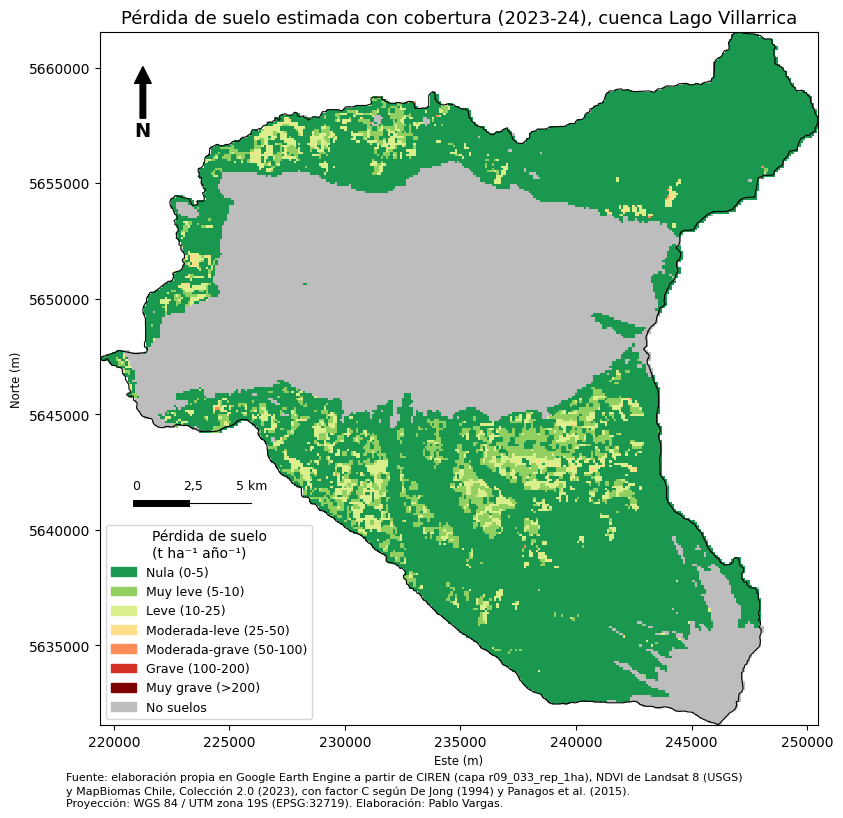

In [ ]:
# Figura 2. Mapa estático de la pérdida de suelo con cobertura (2023-24)

# Se asigna un 8 donde no hay suelo para pintarlo en gris, igual que en la Figura 1.
# unmask(8) marca así el lago, la zona urbana y las clases sin suelo de MapBiomas (~100 ha),
# y updateMask(clases_ciren.mask()) deja sin dato lo que está fuera de la unidad
clases_figura2 = (clase_2324.unmask(8)
                  .updateMask(clases_ciren.mask())
                  .toInt16()            # se usa un tipo entero general para que sampleRectangle acepte el 0 como valor por defecto
                  .rename('clase'))

# Se trae como matriz a 100 m, igual que la Figura 1, para que ambos mapas tengan la misma resolución
matriz2 = np.array(clases_figura2.reproject(crs='EPSG:32719', scale=100)
                   .sampleRectangle(region=region, defaultValue=0)
                   .get('clase').getInfo())
matriz2 = matriz2.astype(float)
matriz2[matriz2 == 0] = np.nan          # lo que está fuera de la unidad queda sin color

fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(matriz2, cmap=paleta, norm=limites, extent=[xmin, xmax, ymin, ymax], interpolation='nearest')
gp_df_simple.boundary.plot(ax=ax, color='black', linewidth=0.8)   # el contorno delimita la unidad sobre el fondo blanco

# Leyenda con la nomenclatura y los rangos de CIREN, igual que la Figura 1, para comparar ambos mapas directamente
elementos = []
for codigo in range(1, 8):
    elementos.append(Patch(color=colores[codigo - 1],
                           label=f"{CLASES_CIREN[codigo][1]} ({CLASES_CIREN[codigo][0]})"))
elementos.append(Patch(color='#bdbdbd', label='No suelos'))
ax.legend(handles=elementos, title='Pérdida de suelo\n(t ha⁻¹ año⁻¹)', loc='lower left', fontsize=9, title_fontsize=10)

ax.annotate('N', xy=(0.06, 0.95), xytext=(0.06, 0.85), xycoords='axes fraction', ha='center', # norte
            fontsize=14, fontweight='bold', arrowprops=dict(facecolor='black', width=4, headwidth=12))

# Escala gráfica de 5 km.
x0 = xmin + 0.05 * (xmax - xmin)
y0 = ymin + 0.32 * (ymax - ymin)
ax.plot([x0, x0 + 2500], [y0, y0], color='black', linewidth=5)
ax.plot([x0 + 2500, x0 + 5000], [y0, y0], color='white', linewidth=5)
ax.plot([x0, x0 + 5000], [y0, y0], color='black', linewidth=0.8)
ax.text(x0, y0 + 600, '0', ha='center', fontsize=9)
ax.text(x0 + 2500, y0 + 600, '2,5', ha='center', fontsize=9)
ax.text(x0 + 5000, y0 + 600, '5 km', ha='center', fontsize=9)

ax.set_title('Pérdida de suelo estimada con cobertura (2023-24), cuenca Lago Villarrica', fontsize=13)
ax.set_xlabel('Este (m)')
ax.set_ylabel('Norte (m)')
ax.ticklabel_format(style='plain')

fig.text(0.12, 0.02,
         'Fuente: elaboración propia en Google Earth Engine a partir de CIREN (capa r09_033_rep_1ha), NDVI de Landsat 8 (USGS)\n'
         'y MapBiomas Chile, Colección 2.0 (2023), con factor C según De Jong (1994) y Panagos et al. (2015).\n'
         'Proyección: WGS 84 / UTM zona 19S (EPSG:32719). Elaboración: Pablo Vargas.',
         fontsize=8)

fig.savefig('/content/drive/MyDrive/RUSLE/figura2_perdida_2023_24_gee.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# --- Aporte de cada clase de cobertura a la pérdida de suelo total (escenario 2023-24) ---

# Pérdida total de cada píxel en toneladas por año: tasa (t/ha/año) × superficie del píxel (ha).
# Aquí se suman toneladas por año (un total), no se promedian tasas. Como en los inventarios del plan de descontaminación, que se expresan en t/año.
t_anio = A_2324.multiply(ee.Image.pixelArea().divide(1e4)).rename('t_anio')
ha_suelo = ee.Image.pixelArea().divide(1e4).updateMask(A_2324.mask()).rename('ha')   # misma superficie que el escenario

# Suma agrupada por clase de MapBiomas 2023 (el mapa que se usa en ambos periodos)
reductor_clase = ee.Reducer.sum().group(groupField=1, groupName='clase')
t_por_clase = t_anio.addBands(clase_mb_2023).reduceRegion(reductor_clase, area_de_interes.geometry(),
                                                          crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()
ha_por_clase_mb = ha_suelo.addBands(clase_mb_2023).reduceRegion(reductor_clase, area_de_interes.geometry(),
                                                                crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()

# Diccionarios "código de clase → valor", para combinar ambos resultados
t_clase = {}
for g in t_por_clase['groups']:
    t_clase[int(g['clase'])] = g['sum']
ha_clase = {}
for g in ha_por_clase_mb['groups']:
    ha_clase[int(g['clase'])] = g['sum']

total_t = sum(t_clase.values())
total_ha = sum(ha_clase.values())

NOMBRES_MB = {3: 'Bosque', 59: 'Bosque primario', 60: 'Bosque secundario', 9: 'Silvicultura',
              67: 'Bosque achaparrado', 66: 'Matorral', 12: 'Pastizal', 63: 'Estepa', 11: 'Humedal',
              15: 'Pastura', 18: 'Agricultura', 25: 'Otra área sin vegetación'}

# Si una clase aporta a la pérdida total mucho más que su porcentaje de superficie, es una fuente
# desproporcionada de sedimento: es lo que pone a prueba la hipótesis
filas = []
for codigo in NOMBRES_MB:
    if codigo in ha_clase:
        filas.append({'Clase': NOMBRES_MB[codigo],
                      'ha': ha_clase[codigo],
                      '% superficie': 100 * ha_clase[codigo] / total_ha,
                      't/año': t_clase.get(codigo, 0),
                      '% pérdida total': 100 * t_clase.get(codigo, 0) / total_t,
                      'Pérdida media (t/ha/año)': t_clase.get(codigo, 0) / ha_clase[codigo]})
tabla_aporte = pd.DataFrame(filas).sort_values('% pérdida total', ascending=False)

print(tabla_aporte.round(1).to_string(index=False))
print(f"\nPérdida total del escenario 2023-24: {total_t:,.0f} t/año sobre {total_ha:,.0f} ha de suelo")
tabla_aporte.round(2).to_csv('etapa3_aporte_por_clase.csv', index=False, encoding='utf-8-sig')


# --- Franja ribereña: suelo a menos de 500 m del agua ---

# agua vale 1 en el agua y 0 en tierra; distance calcula, en cada píxel de tierra, la distancia al agua más cercana
# (sin selfMask, porque con él la tierra queda sin dato y la distancia no se calcula ahí)
distancia_agua = agua.distance(ee.Kernel.euclidean(500, 'meters'))
ribera = distancia_agua.lte(500).unmask(0).toInt().rename('ribera') #toInt() asegura valores enteros, para que la agrupación tenga solo dos grupos: dentro y fuera de la franja

reductor_ribera = ee.Reducer.sum().group(groupField=1, groupName='ribera')
t_por_zona = t_anio.addBands(ribera).reduceRegion(reductor_ribera, area_de_interes.geometry(),
                                                  crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()
ha_por_zona = ha_suelo.addBands(ribera).reduceRegion(reductor_ribera, area_de_interes.geometry(),
                                                     crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()

t_zona = {}
for g in t_por_zona['groups']:
    t_zona[int(g['ribera'])] = g['sum']
ha_zona = {}
for g in ha_por_zona['groups']:
    ha_zona[int(g['ribera'])] = g['sum']

print()
for codigo, nombre in [(1, 'Franja ribereña (< 500 m del agua)'), (0, 'Resto de la cuenca')]:
    print(f"{nombre}: {100 * ha_zona.get(codigo, 0) / total_ha:.1f}% de la superficie | "
          f"{100 * t_zona.get(codigo, 0) / total_t:.1f}% de la pérdida total | "
          f"pérdida media {t_zona.get(codigo, 0) / ha_zona.get(codigo, 1):.2f} t/ha/año")

                   Clase      ha  % superficie   t/año  % pérdida total  Pérdida media (t/ha/año)
                 Pastura  5841.1          20.4 68015.5             81.9                      11.6
             Agricultura   610.1           2.1 11309.8             13.6                      18.5
            Silvicultura  2487.1           8.7  1124.8              1.4                       0.5
       Bosque secundario 10656.9          37.2   843.8              1.0                       0.1
                Matorral   894.2           3.1   739.5              0.9                       0.8
         Bosque primario  7610.4          26.5   413.3              0.5                       0.1
                 Humedal   421.6           1.5   344.9              0.4                       0.8
                Pastizal    54.3           0.2   142.7              0.2                       2.6
Otra área sin vegetación    23.1           0.1    58.4              0.1                       2.5
      Bosque achapar

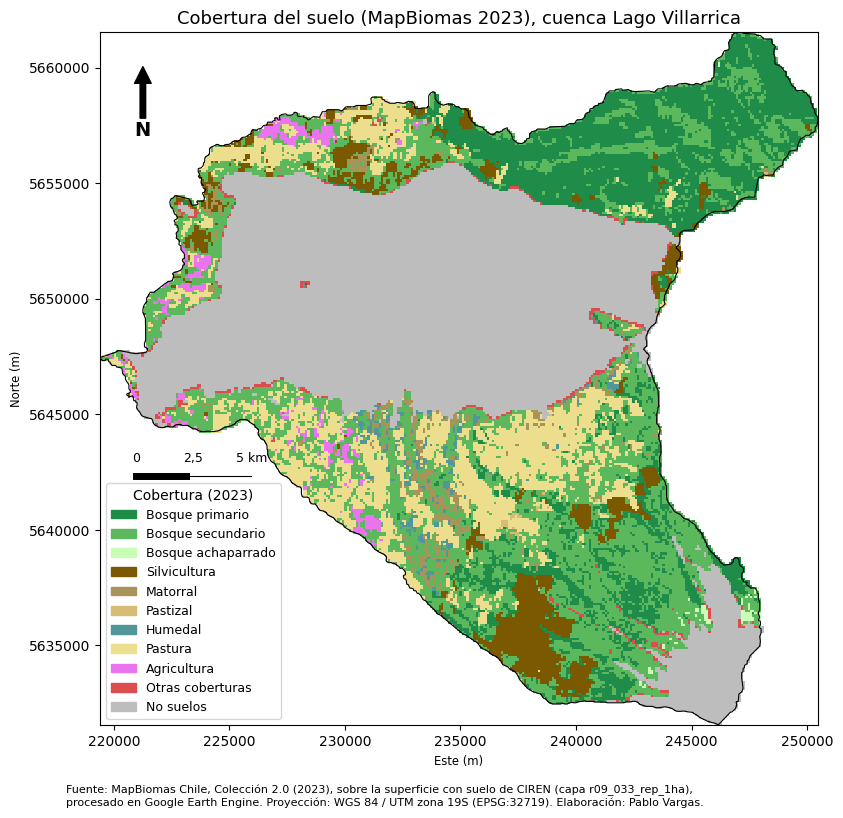

In [ ]:
# Figura 3. Cobertura de MapBiomas 2023 sobre el suelo
# Usa xmin, ymin, xmax, ymax y region, definidos en el mapa de la Etapa 1 (E1.7)

# Cada código de MapBiomas se reemplaza por un número de 1 a 10 para que la paleta tenga un color por clase.
# Otra área sin vegetación y las clases sin suelo según MapBiomas (arena, infraestructura, roca, agua y hielo)
# se agrupan en "Otras coberturas", porque juntas suman muy poca superficie y no se distinguirían en el mapa
codigos_fig3 = [59, 60, 67, 9, 66, 12, 11, 15, 18, 25, 23, 24, 29, 33, 34]
valores_fig3 = [1,  2,  3,  4, 5,  6,  7,  8,  9,  10, 10, 10, 10, 10, 10]

# Se muestra solo la cobertura sobre el suelo de CIREN, que es donde se calculó la pérdida.
# unmask(11) marca No suelos para pintarlo en gris, el segundo updateMask deja sin dato lo que está fuera de la unidad,
# y toInt16 se usa para que sampleRectangle acepte el 0 como valor por defecto
cobertura_figura3 = (clase_mb_2023.remap(codigos_fig3, valores_fig3)
                     .updateMask(mascara_suelos)
                     .unmask(11)
                     .updateMask(clases_ciren.mask())
                     .toInt16()
                     .rename('clase'))

# Se trae como matriz a 100 m, igual que las figuras anteriores, para que todos los mapas tengan la misma resolución
matriz3 = np.array(cobertura_figura3.reproject(crs='EPSG:32719', scale=100)
                   .sampleRectangle(region=region, defaultValue=0)
                   .get('clase').getInfo()).astype(float)
matriz3[matriz3 == 0] = np.nan          # lo que está fuera de la unidad queda sin color

# Se usan los colores oficiales de la leyenda de MapBiomas Chile (Colección 2.0), para que se reconozca la fuente
nombres3 = ['Bosque primario', 'Bosque secundario', 'Bosque achaparrado', 'Silvicultura', 'Matorral',
            'Pastizal', 'Humedal', 'Pastura', 'Agricultura', 'Otras coberturas', 'No suelos']
colores3 = ['#1F8D49', '#5CB85D', '#C8FFB4', '#7A5900', '#A89358',
            '#D6BC74', '#519799', '#EDDE8E', '#E974ED', '#DB4D4F', '#bdbdbd']
paleta3 = ListedColormap(colores3)
limites3 = BoundaryNorm(np.arange(0.5, 12.5, 1), paleta3.N)   # cada valor entero de 1 a 11 recibe un solo color

fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(matriz3, cmap=paleta3, norm=limites3, extent=[xmin, xmax, ymin, ymax], interpolation='nearest')
gp_df_simple.boundary.plot(ax=ax, color='black', linewidth=0.8)   # el contorno delimita la unidad sobre el fondo blanco

# Leyenda con un cuadro de color por cobertura
elementos = []
for i in range(len(nombres3)):
    elementos.append(Patch(color=colores3[i], label=nombres3[i]))
ax.legend(handles=elementos, title='Cobertura (2023)', loc='lower left', fontsize=9, title_fontsize=10)

# Flecha de norte, que la rúbrica exige en cada mapa
ax.annotate('N', xy=(0.06, 0.95), xytext=(0.06, 0.85), xycoords='axes fraction', ha='center',
            fontsize=14, fontweight='bold', arrowprops=dict(facecolor='black', width=4, headwidth=12))

# Escala gráfica de 5 km
x0 = xmin + 0.05 * (xmax - xmin)
y0 = ymin + 0.36 * (ymax - ymin)
ax.plot([x0, x0 + 2500], [y0, y0], color='black', linewidth=5)
ax.plot([x0 + 2500, x0 + 5000], [y0, y0], color='white', linewidth=5)
ax.plot([x0, x0 + 5000], [y0, y0], color='black', linewidth=0.8)
ax.text(x0, y0 + 600, '0', ha='center', fontsize=9)
ax.text(x0 + 2500, y0 + 600, '2,5', ha='center', fontsize=9)
ax.text(x0 + 5000, y0 + 600, '5 km', ha='center', fontsize=9)

ax.set_title('Cobertura del suelo (MapBiomas 2023), cuenca Lago Villarrica', fontsize=13)
ax.set_xlabel('Este (m)')
ax.set_ylabel('Norte (m)')
ax.ticklabel_format(style='plain')

fig.text(0.12, 0.02,
         'Fuente: MapBiomas Chile, Colección 2.0 (2023), sobre la superficie con suelo de CIREN (capa r09_033_rep_1ha),\n'
         'procesado en Google Earth Engine. Proyección: WGS 84 / UTM zona 19S (EPSG:32719). Elaboración: Pablo Vargas.',
         fontsize=8)


fig.savefig('/content/drive/MyDrive/RUSLE/figura3_cobertura_2023_gee.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Umbrales de tolerancia. Superficie de suelo que supera cada umbral

# Se usan umbrales chilenos de origen distinto, que no se homogeneizan porque responden preguntas distintas.
# Formación de suelo (2 y 8 t/ha/año) es el rango de la tasa de formación de Andisoles y Ultisoles del sur de Chile
# (Ellies, 2000). Es un criterio de sostenibilidad, porque por sobre él el suelo se pierde más rápido de lo que se forma.
# Trumao (5 t/ha/año) es la tolerancia estimada para suelos volcánicos con 13 a 18% de pendiente (Peña, 1985),
# usada también para pendientes mayores. Es un criterio productivo local.
# Máxima tolerable (12,36 t/ha/año) es el umbral de la evaluación nacional de erosión hídrica (Núñez-Hidalgo et al., 2025)
UMBRALES = [('Formación de suelo, mín.', 2.0), ('Trumao', 5.0),
            ('Formación de suelo, máx.', 8.0), ('Máxima tolerable', 12.36)]

print("Superficie de suelo sobre cada umbral, por escenario")
for nombre_esc, A in [('CIREN potencial', A_pot), ('C 2013-14', A_1314), ('C 2023-24', A_2324)]:
    # Se calcula la superficie de suelo de cada escenario para expresar el resultado como porcentaje
    ha_total = ha.updateMask(A.mask()).reduceRegion(ee.Reducer.sum(), area_de_interes.geometry(),
                                                    crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()
    total = list(ha_total.values())[0]
    texto = f"{nombre_esc:<16}"
    for nombre_u, T in UMBRALES:
        # Se usa "supera" (gt) porque el umbral es el máximo aceptable, y los valores justo en el umbral
        # son en gran parte efecto del redondeo de la capa de CIREN. Solo se suman los píxeles sobre el umbral
        ha_sobre = ha.updateMask(A.gt(T)).reduceRegion(ee.Reducer.sum(), area_de_interes.geometry(),
                                                       crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()
        sobre = list(ha_sobre.values())[0]
        texto = texto + f" | > {T}: {sobre:,.0f} ha ({100 * sobre / total:.1f}%)"
    print(texto)

# Se repite con distintos pisos de la pastura (escenario 2023-24), porque la superficie sobre cada umbral
# depende mucho de ese supuesto y conviene informar el rango y no un solo valor
print("\nSensibilidad al piso de la pastura (2023-24)")
for piso_pastura in [0.05, 0.10, 0.15]:
    pisos_prueba = [0.0001, 0.0001, 0.0001, 0.0001, 0.003, 0.01, 0.01, 0.01, 0.01, piso_pastura, 0.20, 0.1]
    C_prueba = C_dejong_2324.max(clase_mb_2023.remap(codigos_mb, pisos_prueba)).updateMask(mascara_suelos)
    A_prueba = A_pot.multiply(C_prueba)
    texto = f"Piso pastura = {piso_pastura}"
    for nombre_u, T in UMBRALES:
        ha_sobre = ha.updateMask(A_prueba.gt(T)).reduceRegion(ee.Reducer.sum(), area_de_interes.geometry(),
                                                              crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()
        texto = texto + f" | > {T}: {list(ha_sobre.values())[0]:,.0f} ha"
    print(texto)

# Se calcula qué porcentaje de cada cobertura supera cada umbral (2023-24), para saber dónde intervenir primero.
# ha_clase y NOMBRES_MB vienen de la celda de aporte por clase
print("\nPorcentaje de cada clase sobre el umbral (2023-24)")
for nombre_u, T in UMBRALES:
    res = (ha.updateMask(A_2324.gt(T)).addBands(clase_mb_2023)
           .reduceRegion(ee.Reducer.sum().group(groupField=1, groupName='clase'), area_de_interes.geometry(),
                         crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo())
    sobre_clase = {}
    for g in res['groups']:
        sobre_clase[int(g['clase'])] = g['sum']
    print(f"Umbral {nombre_u} ({T} t/ha/año):")
    for codigo in NOMBRES_MB:
        if codigo in ha_clase:
            print(f"   {NOMBRES_MB[codigo]:<26}{100 * sobre_clase.get(codigo, 0) / ha_clase[codigo]:>6.1f}%")

Superficie de suelo sobre cada umbral, por escenario
CIREN potencial  | > 2.0: 25,479 ha (88.5%) | > 5.0: 25,291 ha (87.8%) | > 8.0: 25,144 ha (87.3%) | > 12.36: 24,867 ha (86.4%)
C 2013-14        | > 2.0: 6,087 ha (21.2%) | > 5.0: 5,300 ha (18.5%) | > 8.0: 4,029 ha (14.0%) | > 12.36: 1,929 ha (6.7%)
C 2023-24        | > 2.0: 6,138 ha (21.4%) | > 5.0: 5,333 ha (18.6%) | > 8.0: 4,053 ha (14.1%) | > 12.36: 1,934 ha (6.7%)

Sensibilidad al piso de la pastura (2023-24)
Piso pastura = 0.05 | > 2.0: 5,767 ha | > 5.0: 2,182 ha | > 8.0: 2,068 ha | > 12.36: 903 ha
Piso pastura = 0.1 | > 2.0: 6,138 ha | > 5.0: 5,333 ha | > 8.0: 4,053 ha | > 12.36: 1,934 ha
Piso pastura = 0.15 | > 2.0: 6,271 ha | > 5.0: 5,854 ha | > 8.0: 5,232 ha | > 12.36: 3,925 ha

Porcentaje de cada clase sobre el umbral (2023-24)
Umbral Formación de suelo, mín. (2.0 t/ha/año):
   Bosque primario              0.1%
   Bosque secundario            0.7%
   Silvicultura                 3.6%
   Bosque achaparrado           0.2%
   

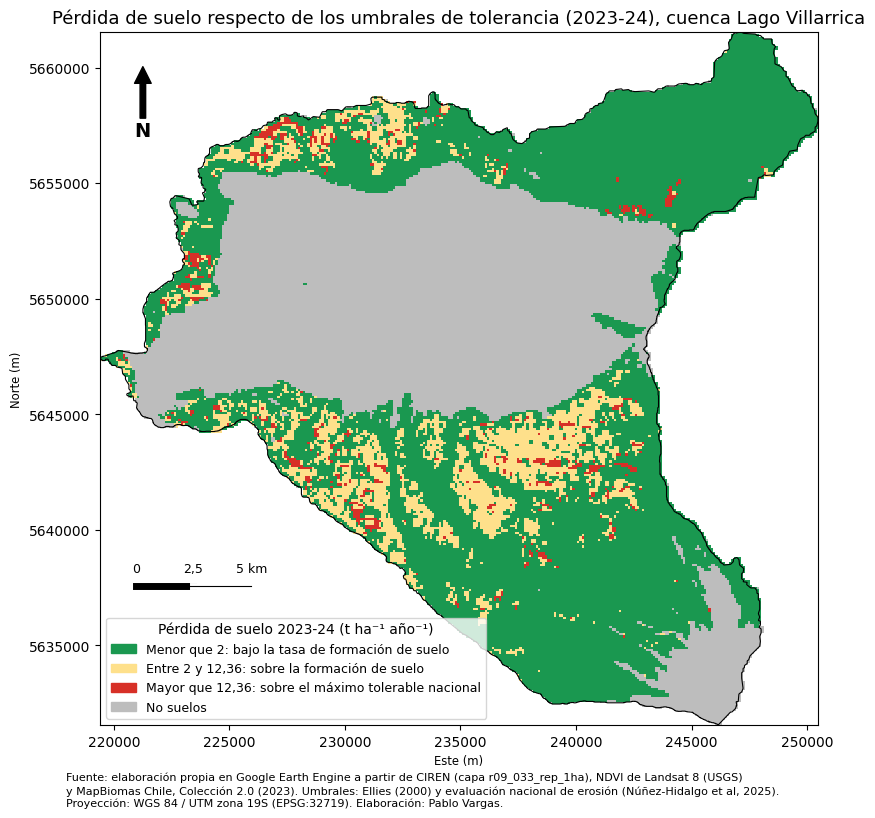

In [ ]:
# Figura 4. Nivel de pérdida respecto de los umbrales de tolerancia (2023-24), para el informe
# Usa xmin, ymin, xmax, ymax y region, definidos en el mapa de la Etapa 1 (E1.7)

# Tres niveles con los umbrales extremos: 2 t/ha/año (formación de suelo, Ellies, 2000) y 12,36 t/ha/año
# (máximo tolerable nacional, Núñez-Hidalgo et al, 2025 ). Se usa "supera" (gt), igual que en la celda de umbrales.
nivel = (ee.Image(1)
         .where(A_2324.gt(2), 2)          # sobre la tasa de formación de suelo
         .where(A_2324.gt(12.36), 3)      # además, sobre el máximo tolerable nacional
         .updateMask(A_2324.mask()))      # la imagen de partida cubre todo, se limita al suelo con escenario

# unmask(4) asigna 4 a No suelos y updateMask deja sin dato lo que está fuera de la unidad
nivel_figura4 = (nivel.unmask(4)
                 .updateMask(clases_ciren.mask())
                 .toInt16()
                 .rename('nivel'))

matriz4 = np.array(nivel_figura4.reproject(crs='EPSG:32719', scale=100)
                   .sampleRectangle(region=region, defaultValue=0)
                   .get('nivel').getInfo()).astype(float)
matriz4[matriz4 == 0] = np.nan

nombres4 = ['Menor que 2: bajo la tasa de formación de suelo',
            'Entre 2 y 12,36: sobre la formación de suelo',
            'Mayor que 12,36: sobre el máximo tolerable nacional',
            'No suelos']
colores4 = ['#1a9850', '#fee08b', '#d73027', '#bdbdbd']
paleta4 = ListedColormap(colores4)
limites4 = BoundaryNorm(np.arange(0.5, 5.5, 1), paleta4.N)   # un color por valor entero de 1 a 4

fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(matriz4, cmap=paleta4, norm=limites4, extent=[xmin, xmax, ymin, ymax], interpolation='nearest')
gp_df_simple.boundary.plot(ax=ax, color='black', linewidth=0.8)

elementos = []
for i in range(len(nombres4)):
    elementos.append(Patch(color=colores4[i], label=nombres4[i]))
ax.legend(handles=elementos, title='Pérdida de suelo 2023-24 (t ha⁻¹ año⁻¹)', loc='lower left',
          fontsize=9, title_fontsize=10)

ax.annotate('N', xy=(0.06, 0.95), xytext=(0.06, 0.85), xycoords='axes fraction', ha='center', # norte
            fontsize=14, fontweight='bold', arrowprops=dict(facecolor='black', width=4, headwidth=12))

# Escala gráfica de 5 km
x0 = xmin + 0.05 * (xmax - xmin)
y0 = ymin + 0.20 * (ymax - ymin)
ax.plot([x0, x0 + 2500], [y0, y0], color='black', linewidth=5)
ax.plot([x0 + 2500, x0 + 5000], [y0, y0], color='white', linewidth=5)
ax.plot([x0, x0 + 5000], [y0, y0], color='black', linewidth=0.8)
ax.text(x0, y0 + 600, '0', ha='center', fontsize=9)
ax.text(x0 + 2500, y0 + 600, '2,5', ha='center', fontsize=9)
ax.text(x0 + 5000, y0 + 600, '5 km', ha='center', fontsize=9)

ax.set_title('Pérdida de suelo respecto de los umbrales de tolerancia (2023-24), cuenca Lago Villarrica', fontsize=13)
ax.set_xlabel('Este (m)')
ax.set_ylabel('Norte (m)')
ax.ticklabel_format(style='plain')

fig.text(0.12, 0.02,
         'Fuente: elaboración propia en Google Earth Engine a partir de CIREN (capa r09_033_rep_1ha), NDVI de Landsat 8 (USGS)\n'
         'y MapBiomas Chile, Colección 2.0 (2023). Umbrales: Ellies (2000) y evaluación nacional de erosión (Núñez-Hidalgo et al, 2025).\n'
         'Proyección: WGS 84 / UTM zona 19S (EPSG:32719). Elaboración: Pablo Vargas.',
         fontsize=8)

fig.savefig('/content/drive/MyDrive/RUSLE/figura4_umbrales_2023_24_gee.png', dpi=300, bbox_inches='tight')
plt.show()

### Contraste con la capa actual de CIREN y calidad de la capa potencial

In [ ]:
# Capa de pérdida actual de CIREN, la voy a usar para contrastar el escenario propio con la estimación oficial (anexo D)
gp_rea = gpd.read_file('/content/drive/MyDrive/RUSLE/r09_033_rea_1ha.gpkg')

# Se comparan las pérdidas medias porque respaldan la cifra del Anexo D, donde la capa actual
# resulta unas 170 veces menor que la potencial.
print(f"Pérdida media actual (REA): {gp_rea['RUSLE'].mean():.2f} t/ha/año")
print(f"Pérdida media potencial (REP): {gp_df['RUSLE'].mean():.2f} t/ha/año")

Celdas: actual = 30474 | potencial = 30474

Pérdida actual (REA), t/ha/año:
count    30474.00
mean         1.16
std          5.59
min          0.00
25%          0.00
50%          0.02
75%          0.59
max        300.00
Name: RUSLE, dtype: float64

Pérdida potencial (REP), t/ha/año:
count    30474.00
mean       198.89
std        175.13
min          0.00
25%         70.00
50%        100.00
75%        300.00
max        500.00
Name: RUSLE, dtype: float64


In [ ]:
# Capa actual de CIREN sobre suelo, para comparar con el escenario 2023-24
# Solo clases 1 a 7, las celdas de No suelos tienen pérdida 0 y bajarían el promedio
gp_rea['cod_num'] = gp_rea['COD_RANGO'].astype(int)
suelo_rea = gp_rea[gp_rea['cod_num'] <= 7]
print(f"Pérdida media actual de CIREN sobre suelo: {suelo_rea['RUSLE'].mean():.2f} t/ha/año")

# Superficie por clase, con la misma nomenclatura que la tabla de los escenarios (etapa 3)
ha_rea = suelo_rea.groupby('cod_num')['AREA_HA'].sum()
total_rea = ha_rea.sum()
for codigo in range(1, 8):
    ha_c_rea = ha_rea.get(codigo, 0)
    print(f"{CLASES_CIREN[codigo][1]:<16}{ha_c_rea:>10,.1f} ha  {100 * ha_c_rea / total_rea:>5.1f}%")

# Si hay pocos valores distintos,  la potencial está discretizada y eso limita la precisión del escenario modificado (CIREN × C)
print("\nValores distintos de RUSLE en la potencial:", gp_df['RUSLE'].nunique())
print(gp_df['RUSLE'].value_counts().head(10))

Pérdida media actual de CIREN sobre suelo: 1.16 t/ha/año
Nula              26,105.9 ha   93.8%
Muy leve           1,072.3 ha    3.9%
Leve                 546.1 ha    2.0%
Moderada-leve         84.4 ha    0.3%
Moderada-grave        20.0 ha    0.1%
Grave                 10.0 ha    0.0%
Muy grave              4.6 ha    0.0%

Valores distintos de RUSLE en la potencial: 822
RUSLE
500.0    5706
200.0    5511
100.0    5323
0.0      3397
300.0    2315
400.0    1291
90.0     1050
80.0      994
70.0      901
60.0      777
Name: count, dtype: int64


In [ ]:
# La tabla de la celda anterior muestra que los valores de la capa potencial están redondeados y topados en 500 t/ha/año.
# El valor real de las celdas topadas se perdió y no se puede recuperar. Para acotar su efecto, se supone que
# su pérdida potencial real era 1,5 o 2 veces el tope (750 o 1.000 t/ha/año) y se recalcula el escenario 2023-24.
print()
for factor in [1, 1.5, 2]:
    # Solo se modifican las celdas exactamente en 500; el resto de la capa potencial queda igual
    A_pot_prueba = A_pot.where(A_pot.gte(500), A_pot.multiply(factor))
    media_prueba = A_pot_prueba.multiply(C_2324).reduceRegion(ee.Reducer.mean(), area_de_interes.geometry(),
                                                              crs='EPSG:32719', scale=30, maxPixels=1e10).getInfo()
    print(f"Celdas topadas × {factor}: pérdida media 2023-24 = {list(media_prueba.values())[0]:.3f} t/ha/año")


Celdas topadas × 1: pérdida media 2023-24 = 2.895 t/ha/año
Celdas topadas × 1.5: pérdida media 2023-24 = 2.962 t/ha/año
Celdas topadas × 2: pérdida media 2023-24 = 3.029 t/ha/año


In [ ]:
# Exportación de capas a Google Drive para armar los mapas del informe en QGIS (al final lo hice acá, pero dejo la celda para el registro :p)

# En todas las capas, el valor 0 significa "sin dato" (lago, zona urbana, roca), y en un SIG se marca como transparente

# 1) Clasificación del escenario 2023-24 con las clases de CIREN, de 1 (Nula) a 7 (Muy grave)
clase_2324_export = clase_2324.unmask(0).toByte()   # toByte reduce el tamaño del archivo, porque los valores son enteros pequeños

# 2) Nivel respecto de los umbrales de tolerancia (2023-24). Se usan los dos extremos porque muestran que la conclusión
#    depende del criterio. 1 = bajo 2 t/ha/año (bajo la tasa de formación de suelo), 2 = entre 2 y 12,36,
#    3 = sobre 12,36 (máximo tolerable nacional). Se usa "supera" (gt), igual que en la celda de umbrales
nivel_tolerancia = (ee.Image(1).where(A_2324.gt(2), 2).where(A_2324.gt(12.36), 3)
                    .updateMask(A_2324.mask()))      # la imagen de partida cubre todo el planeta, por eso se limita al suelo
nivel_tolerancia_export = nivel_tolerancia.unmask(0).toByte()

# 3) Cobertura de MapBiomas 2023 sobre el suelo, para ver dónde están las praderas y cultivos que concentran la pérdida.
#    Cada píxel conserva su código de MapBiomas, cuya leyenda está en el PDF de códigos de la Colección 2
cobertura_export = clase_mb_2023.updateMask(mascara_suelos).unmask(0).toByte()

# 4) Cambio de clase de CIREN entre periodos, para ubicar dónde aumentó o disminuyó la pérdida.
#    1 = bajó, 2 = sin cambio, 3 = subió
cambio_clase = (ee.Image(2).where(clase_2324.lt(clase_1314), 1).where(clase_2324.gt(clase_1314), 3)
                .updateMask(clase_2324.mask()))
cambio_clase_export = cambio_clase.unmask(0).toByte()

capas = [('rusle_clases_2023_24', clase_2324_export),
         ('rusle_nivel_tolerancia_2023_24', nivel_tolerancia_export),
         ('mapbiomas_2023_suelo', cobertura_export),
         ('rusle_cambio_clase_2013_2023', cambio_clase_export)]

for nombre, imagen in capas:
    tarea = ee.batch.Export.image.toDrive(
        image=imagen,
        description=nombre,
        folder='RUSLE',
        region=area_de_interes.geometry(),
        scale=30,
        crs='EPSG:32719',
        maxPixels=1e10,
        fileFormat='GeoTIFF')
    tarea.start()
    print(f"Exportación iniciada:  {nombre}.tif")

Exportación iniciada:  rusle_clases_2023_24.tif
Exportación iniciada:  rusle_nivel_tolerancia_2023_24.tif
Exportación iniciada:  mapbiomas_2023_suelo.tif
Exportación iniciada:  rusle_cambio_clase_2013_2023.tif
